In [1]:
import torch
from utilities import (
    set_seed, load_and_combine_datasets, create_dataloaders,
    get_single_model, train_model, test_and_report, visualize_gradcam_samples, load_trained_model
)

# 1. Setup

In [2]:
set_seed(42)
device = torch.device("cpu")

# 2. Data

In [3]:
df = load_and_combine_datasets()
train_loader, val_loader, test_loader, test_ds = create_dataloaders(df, batch_size=16)

[Dataset] Loaded 368 images total.
[Splits] Train: 257 | Val: 55 | Test: 56


# 3. Choose your model: 
    1. resnet50 
    2. vgg16_bn 
    3. densenet121 
    4. efficientnet_b0

In [4]:
MODEL_NAME = "efficientnet_b0"
model, target_layer = get_single_model(MODEL_NAME, freeze_backbone=True)

[EFFICIENTNET_B0] Total: 4,336,510 | Trainable: 328,962 (7.59%)


# 4. Train Single Model

In [5]:
model, history = train_model(
    model, train_loader, val_loader, device, 
    epochs=30, lr=1e-3, model_name=MODEL_NAME, resume=True
)

Epoch [01/30] Train Loss: 0.4685 Acc: 0.7656 | Val Loss: 0.4394 Acc: 0.7818 (Best: 0.7818)
Epoch [02/30] Train Loss: 0.2588 Acc: 0.9102 | Val Loss: 0.2430 Acc: 0.9455 (Best: 0.9455)
Epoch [03/30] Train Loss: 0.2692 Acc: 0.8672 | Val Loss: 0.2302 Acc: 0.9273 (Best: 0.9455)
Epoch [04/30] Train Loss: 0.2419 Acc: 0.8828 | Val Loss: 0.1689 Acc: 0.9455 (Best: 0.9455)
Epoch [05/30] Train Loss: 0.2046 Acc: 0.9219 | Val Loss: 0.1929 Acc: 0.9273 (Best: 0.9455)
Epoch [06/30] Train Loss: 0.2106 Acc: 0.9297 | Val Loss: 0.2111 Acc: 0.9273 (Best: 0.9455)
Epoch [07/30] Train Loss: 0.1892 Acc: 0.9062 | Val Loss: 0.1904 Acc: 0.9455 (Best: 0.9455)
Epoch [08/30] Train Loss: 0.1946 Acc: 0.9180 | Val Loss: 0.1669 Acc: 0.9455 (Best: 0.9455)
Epoch [09/30] Train Loss: 0.1809 Acc: 0.9219 | Val Loss: 0.1709 Acc: 0.9455 (Best: 0.9455)
Epoch [10/30] Train Loss: 0.1453 Acc: 0.9375 | Val Loss: 0.1358 Acc: 0.9636 (Best: 0.9636)
Epoch [11/30] Train Loss: 0.1912 Acc: 0.9219 | Val Loss: 0.1014 Acc: 1.0000 (Best: 1.0000)

# 5. Evaluate Single Model on Test Set


==================== EFFICIENTNET_B0 TEST RESULTS ====================
Loss: 0.0617 | Accuracy: 98.21%
Sensitivity (Recall): 96.30% | Specificity: 100.00%
Precision: 100.00% | F1-Score: 0.9811 | ROC-AUC: 1.0000


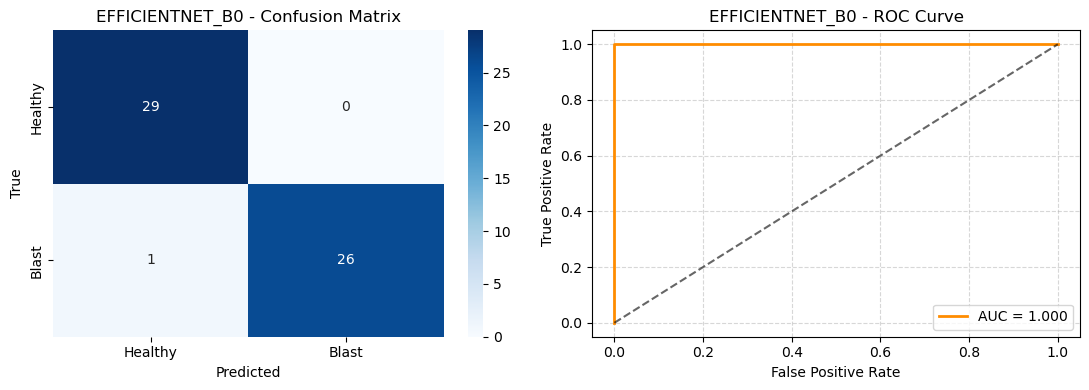

In [6]:
metrics = test_and_report(model, test_loader, device, model_name=MODEL_NAME)

# 6. Explainability with Grad-CAM

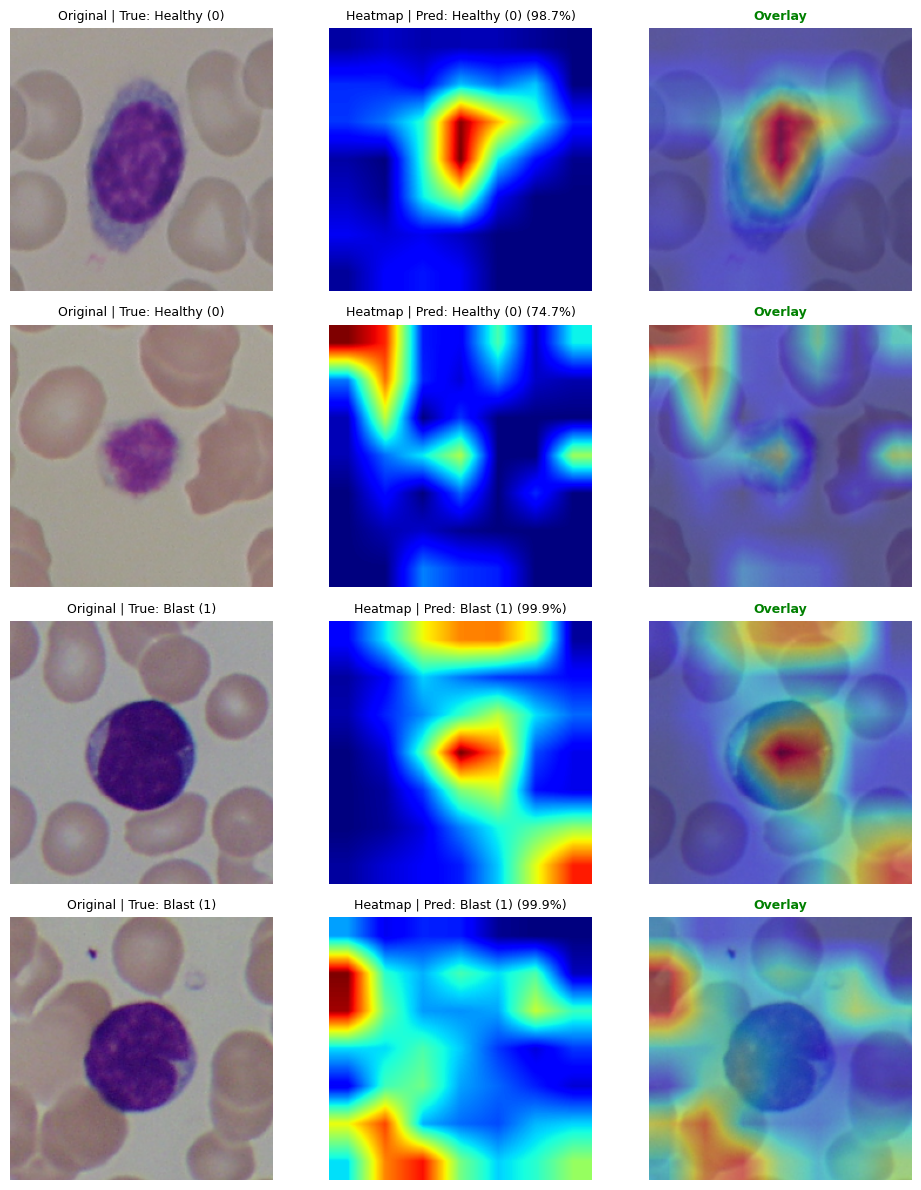

In [7]:
visualize_gradcam_samples(model, target_layer, test_ds, device, num_samples=4)